














































































































































































# Instructions  

  Before starting working at the project you should have

  1. complete the Notebook for the two-station bike-share system
  2. read information about the Belfast bike-share system
  3. discuss with your group how the code for the simple model can be adapted and extended to work for the Belfast bike-share system.

  Information on the Belfast bike-share systems, instructions on how to set up a basic code and data sets are available from [this Canvas page](https://canvas.qub.ac.uk/courses/20095/modules/items/815254).

  For general information on the project, refer instead to [this Canvas page](https://canvas.qub.ac.uk/courses/20095/modules/items/815252)

  **Finally, do not forget to share the Notebook among all group's members on Google Co-lab, as well as with the lecturers.**
  
  Everyone in the group can work at the code.
  
  All members of the group need to have a copy of the input data set available for themselves to run a simulation.
  
  All members of the group may get different results for a simulation, if
  the random number generator has not been provided with a consistent seed-value across all members.
  
  It is thus advised to run the simulations with a seeded random number generator.
  
  To verify stochastic variation, you will need to run the code with different seed values **


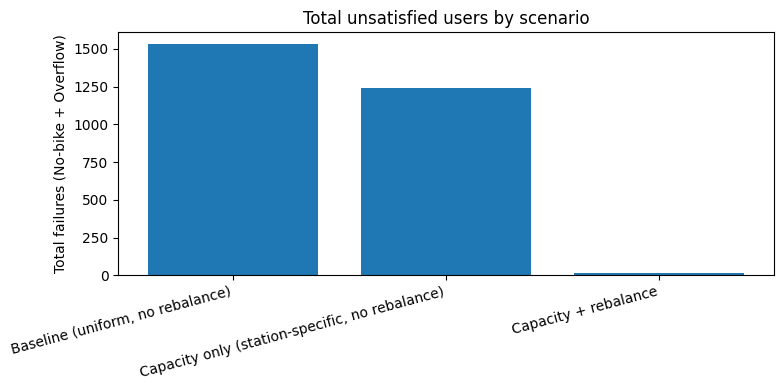

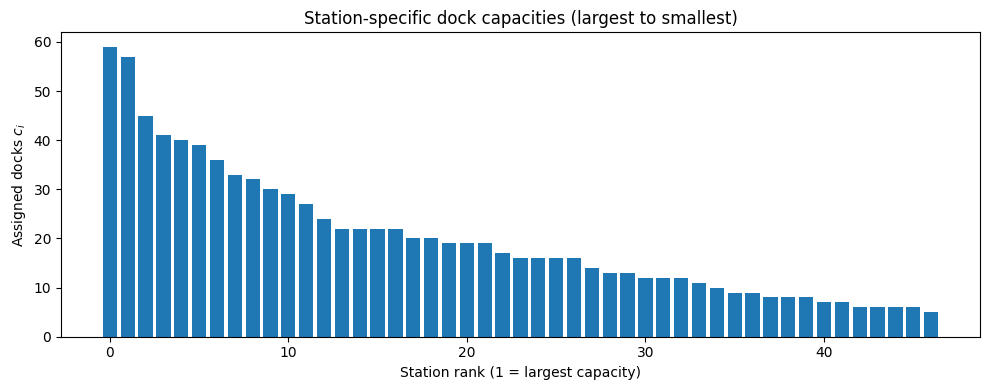

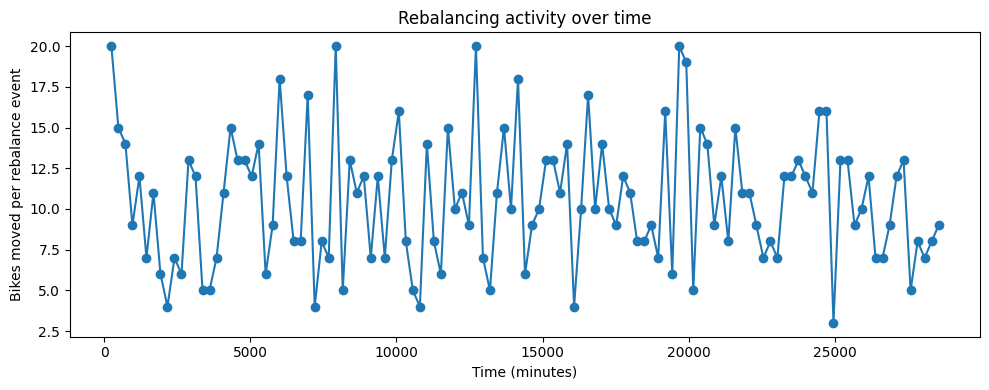

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXCEL_PATH  = "/content/BelfastBikesAprilToOctober (2).xlsx"
PIVOT_SHEET = "Sheet1"

# Dataset window (Apr 1 2021 to Oct 31 2021 inclusive)
START_DATE = "2021-04-01"
END_DATE   = "2021-10-31"

def load_flow_matrix_from_sheet1(excel_path: str, sheet_name: str) -> pd.DataFrame:
    """
    Reads 'Sheet1' pivot format:
      - Station names across row 2 (starting col 1)
      - Station names down col 0 (starting row 3)
      - Bottom row contains end-shares, last column contains start-shares
      - 'Grand Total' column exists
    Returns:
      flows_df: square DataFrame [stations x stations] of trip counts i->j
    """
    raw = pd.read_excel(excel_path, sheet_name=sheet_name, header=None)

    # row 2 (0-indexed) contains column station names starting at col 1
    header_row = 2
    start_row = 3

    col_names = raw.iloc[header_row, 1:].tolist()

    # Trim trailing NaNs
    while len(col_names) > 0 and (col_names[-1] is np.nan or pd.isna(col_names[-1])):
        col_names.pop()

    # Remove "Grand Total" if present in columns
    col_names = [c for c in col_names if isinstance(c, str) and c.strip().lower() != "grand total"]

    # Row station names in first column until we hit "Grand Total" row
    row_names = raw.iloc[start_row:, 0].tolist()
    # Find where "Grand Total" row begins (or first NaN)
    end_idx = None
    for k, rn in enumerate(row_names):
        if not isinstance(rn, str):
            continue
        if rn.strip().lower() == "grand total":
            end_idx = k
            break
    if end_idx is None:
        # fallback: drop last 2 rows if they are totals/prob rows
        end_idx = len(row_names)

    row_names = row_names[:end_idx]
    row_names = [r for r in row_names if isinstance(r, str) and r.strip() != ""]

    # Extract numeric block: rows start_row .. start_row+len(row_names)-1
    # cols: 1 .. 1+len(col_names)-1
    block = raw.iloc[start_row:start_row+len(row_names), 1:1+len(col_names)].copy()
    block = block.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    flows_df = pd.DataFrame(block.values, index=row_names, columns=col_names)

    # Make square (some pivots can have row/col station set mismatch)
    stations = sorted(set(flows_df.index) | set(flows_df.columns))
    flows_df = flows_df.reindex(index=stations, columns=stations, fill_value=0.0)

    # Drop any completely empty stations (safety)
    nonzero = (flows_df.sum(axis=1) + flows_df.sum(axis=0)) > 0
    flows_df = flows_df.loc[nonzero, nonzero]

    return flows_df


def build_markov_inputs(flows_df: pd.DataFrame, start_date: str, end_date: str):
    """
    From counts matrix F_ij build:
      - P_ij = F_ij / sum_j F_ij  (row-normalised)
      - lambda_i per minute from row totals across dataset window
    """
    F = flows_df.to_numpy(dtype=float)
    stations = list(flows_df.index)
    n = len(stations)

    row_totals = F.sum(axis=1)         # starts from i
    total_trips = row_totals.sum()

    # Minutes in dataset window inclusive
    sd = pd.Timestamp(start_date)
    ed = pd.Timestamp(end_date)
    minutes = int(((ed + pd.Timedelta(days=1)) - sd) / pd.Timedelta(minutes=1))

    # Arrivals per minute per station (Poisson rate)
    lam = row_totals / minutes         # expected starts per minute at station i

    # Transition probabilities P_ij
    P = np.zeros((n, n), dtype=float)
    for i in range(n):
        if row_totals[i] > 0:
            P[i, :] = F[i, :] / row_totals[i]
        else:
            # If a station has no outgoing data: self-loop
            P[i, i] = 1.0

    return stations, F, P, lam, minutes, total_trips

def propose_capacities(
    F: np.ndarray,
    total_capacity_budget: int,
    min_cap: int = 10,
    weight_mode: str = "ends"  # "ends" or "activity"
):
    """
    Propose station-specific dock capacities under a total budget.
    - min_cap: minimum docks at every station
    - total_capacity_budget: sum of capacities across all stations
    - weight_mode:
        "ends"     -> allocate extra docks proportional to end counts (reduce overflow)
        "activity" -> allocate extra docks proportional to starts+ends (busy hubs)
    Returns: capacity vector (int) length n
    """
    n = F.shape[0]
    start_counts = F.sum(axis=1)
    end_counts   = F.sum(axis=0)

    if weight_mode == "ends":
        w = end_counts
    elif weight_mode == "activity":
        w = start_counts + end_counts
    else:
        raise ValueError("weight_mode must be 'ends' or 'activity'")

    w = np.asarray(w, dtype=float)
    w = w + 1e-12
    w = w / w.sum()

    # Budget check
    if total_capacity_budget < n * min_cap:
        raise ValueError("total_capacity_budget is too small for the chosen min_cap")

    base = np.full(n, min_cap, dtype=int)
    remaining = total_capacity_budget - base.sum()

    # Allocate remaining docks proportional to weights
    extra = np.floor(remaining * w).astype(int)
    cap = base + extra

    # Fix rounding so sum is exact
    diff = total_capacity_budget - cap.sum()
    if diff > 0:
        # add 1 dock to top-weighted stations until budget filled
        order = np.argsort(-w)
        for k in range(diff):
            cap[order[k % n]] += 1
    elif diff < 0:
        # remove 1 dock from lowest-weighted stations if we overshot
        order = np.argsort(w)
        for k in range(-diff):
            idx = order[k % n]
            if cap[idx] > min_cap:
                cap[idx] -= 1

    return cap

def rebalance_bikes(
    bikes: np.ndarray,
    capacity: np.ndarray,
    lam: np.ndarray,
    max_moves: int = 10,
    low_frac: float = 0.15,
    high_frac: float = 0.85
):
    """
    Rebalance bikes by moving from 'full' stations to 'empty' stations.
    Returns number of bike moves performed.

    receivers: bikes < low_frac * capacity
    donors:    bikes > high_frac * capacity

    Priority:
      - receivers sorted by high lam (demand)
      - donors sorted by surplus
    """
    receivers = np.where(bikes < low_frac * capacity)[0]
    donors = np.where(bikes > high_frac * capacity)[0]

    if len(receivers) == 0 or len(donors) == 0:
        return 0

    # Prioritise receivers by demand (lam high first)
    receivers = receivers[np.argsort(-lam[receivers])]

    # Prioritise donors by surplus (most extra first)
    surplus = bikes[donors] - (high_frac * capacity[donors])
    donors = donors[np.argsort(-surplus)]

    moves = 0
    r_ptr = 0
    d_ptr = 0

    while moves < max_moves and r_ptr < len(receivers) and d_ptr < len(donors):
        r = receivers[r_ptr]
        d = donors[d_ptr]

        # Feasibility checks
        if bikes[d] <= 0:
            d_ptr += 1
            continue
        if bikes[r] >= capacity[r]:
            r_ptr += 1
            continue

        # Move ONE bike (one "truck move" unit)
        bikes[d] -= 1
        bikes[r] += 1
        moves += 1

        # Advance pointers if no longer qualifies
        if bikes[r] >= low_frac * capacity[r]:
            r_ptr += 1
        if bikes[d] <= high_frac * capacity[d]:
            d_ptr += 1

    return moves


def initialise_bikes(total_bikes: int, capacity: np.ndarray, weights: np.ndarray, rng: np.random.Generator):
    """
    Place bikes initially using a multinomial distribution with given weights,
    then clip to capacity and re-place leftovers into stations with free space.
    """
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    bikes = rng.multinomial(total_bikes, weights)
    bikes = np.minimum(bikes, capacity)

    leftover = total_bikes - bikes.sum()
    if leftover > 0:
        free = capacity - bikes
        while leftover > 0 and free.sum() > 0:
            probs = free / free.sum()
            k = rng.choice(len(free), p=probs)
            bikes[k] += 1
            free[k] -= 1
            leftover -= 1
    return bikes


def simulate_bike_share(
    P: np.ndarray,
    lam: np.ndarray,
    capacity,
    total_bikes: int,
    minutes_to_simulate: int,
    seed: int = 1,
    record_every: int = 60,
    # --- Rebalancing controls ---
    rebalance_every: int | None = None,   # None = OFF
    rebalance_max_moves: int = 0,
    rebalance_low_frac: float = 0.15,
    rebalance_high_frac: float = 0.85
):
    rng = np.random.default_rng(seed)
    n = len(lam)

    # capacity can be scalar (uniform) or a vector (station-specific)
    if np.isscalar(capacity):
        capacity = np.full(n, int(capacity), dtype=int)
    else:
        capacity = np.asarray(capacity, dtype=int)
        if len(capacity) != n:
            raise ValueError("capacity vector length must equal number of stations")

    # Init bikes proportional to demand
    init_weights = lam + 1e-12
    bikes = initialise_bikes(total_bikes, capacity, init_weights, rng)

    # Failures + counters
    fail_no_bike = np.zeros(n, dtype=int)
    fail_overflow = np.zeros(n, dtype=int)
    success = 0

    attempted_starts = np.zeros(n, dtype=int)
    successful_starts = np.zeros(n, dtype=int)
    successful_ends = np.zeros(n, dtype=int)
    flow_success = np.zeros((n, n), dtype=int)

    record_t, record_bikes = [], []

    # Rebalance tracking
    total_rebalance_moves = 0
    rebalance_events = 0
    rebalance_moves_t = []   # time series (for plotting)
    rebalance_times = []

    for t in range(minutes_to_simulate):
        # Bernoulli arrivals (<= 1 per station per minute)
        arrivals = (rng.random(n) < lam).astype(int)

        for i in range(n):
            if arrivals[i] == 0:
                continue

            attempted_starts[i] += 1

            if bikes[i] <= 0:
                fail_no_bike[i] += 1
                continue

            j = rng.choice(n, p=P[i, :])

            if bikes[j] >= capacity[j]:
                fail_overflow[j] += 1
                continue

            # Successful customer trip
            bikes[i] -= 1
            bikes[j] += 1
            success += 1

            successful_starts[i] += 1
            successful_ends[j] += 1
            flow_success[i, j] += 1

        # Record state occasionally
        if (t % record_every) == 0:
            record_t.append(t)
            record_bikes.append(bikes.copy())

        # ----- Rebalancing step -----
        if rebalance_every is not None and rebalance_every > 0 and rebalance_max_moves > 0:
            if (t % rebalance_every) == 0 and t > 0:
                moved = rebalance_bikes(
                    bikes=bikes,
                    capacity=capacity,
                    lam=lam,
                    max_moves=rebalance_max_moves,
                    low_frac=rebalance_low_frac,
                    high_frac=rebalance_high_frac
                )
                total_rebalance_moves += moved
                rebalance_events += 1
                rebalance_times.append(t)
                rebalance_moves_t.append(moved)

    record_bikes = np.array(record_bikes)

    return {
        "bikes_final": bikes,
        "capacity": capacity,
        "success": int(success),

        "fail_no_bike_by_station": fail_no_bike,
        "fail_overflow_by_station": fail_overflow,
        "fail_no_bike_total": int(fail_no_bike.sum()),
        "fail_overflow_total": int(fail_overflow.sum()),

        "attempted_starts": attempted_starts,
        "successful_starts": successful_starts,
        "successful_ends": successful_ends,
        "flow_success": flow_success,

        "record_times": np.array(record_t),
        "record_bikes": record_bikes,

        "rebalance_moves_total": int(total_rebalance_moves),
        "rebalance_events": int(rebalance_events),
        "rebalance_moves_per_event": (total_rebalance_moves / rebalance_events) if rebalance_events > 0 else 0.0,
        "rebalance_times": np.array(rebalance_times),
        "rebalance_moves_t": np.array(rebalance_moves_t),
    }


# ============================================================
# RUN IT
# ============================================================

flows_df = load_flow_matrix_from_sheet1(EXCEL_PATH, PIVOT_SHEET)
stations, F, P, lam, minutes_in_dataset, total_trips = build_markov_inputs(flows_df, START_DATE, END_DATE)


# --- Simulation parameters ---
SIM_DAYS = 20
T = SIM_DAYS * 24 * 60

TOTAL_BIKES = 378     #its 378 irl but i'm gonna add loads more to see how they spread
CAPACITY_PER_STATION = 20

def summarize_run(name, out):
    attempted = out["attempted_starts"].sum()
    failures = out["fail_no_bike_total"] + out["fail_overflow_total"]
    fail_rate = failures / max(attempted, 1)

    return {
        "Scenario": name,
        "SuccessTrips": out["success"],
        "AttemptedStarts": int(attempted),
        "NoBikeFails": out["fail_no_bike_total"],
        "OverflowFails": out["fail_overflow_total"],
        "FailRate": fail_rate,
        "TotalBikes": int(out["bikes_final"].sum()),
        "TotalDocks": int(out["capacity"].sum()),
        "FreeDocksEnd": int(out["capacity"].sum() - out["bikes_final"].sum())
    }

baseline_out = simulate_bike_share(
    P=P, lam=lam,
    capacity=CAPACITY_PER_STATION,
    total_bikes=TOTAL_BIKES,
    minutes_to_simulate=T,
    seed=42,
    record_every=6*60,
    rebalance_every=None
)

# ---- Station-specific capacities (same-ish budget) ----
TOTAL_CAPACITY_BUDGET = 940        #1410 is number of docks using what we have before this
#but if we were to get an increased budget we could allocate the docks better
MIN_CAP = 5             #20 seems to be good but i'll try lower ones?
WEIGHT_MODE = "ends"

capacity_vec = propose_capacities(
    F=F,
    total_capacity_budget=TOTAL_CAPACITY_BUDGET,
    min_cap=MIN_CAP,
    weight_mode=WEIGHT_MODE
)

new_out = simulate_bike_share(
    P=P, lam=lam,
    capacity=capacity_vec,
    total_bikes=TOTAL_BIKES,
    minutes_to_simulate=T,
    seed=42,
    record_every=6*60,
    rebalance_every=None
)


reb_out = simulate_bike_share(
    P=P, lam=lam, capacity=capacity_vec,
    total_bikes=TOTAL_BIKES, minutes_to_simulate=T,
    seed=42, record_every=6*60,
    rebalance_every=240,        # every 240 mins, the van moves around bikes, if we have add another person (a van goes out every 120 mins)
    rebalance_max_moves=20,    # size of the van moving the bikes
    rebalance_low_frac=0.25,   # treat <30% as "needs bikes"
    rebalance_high_frac=0.50   # treat >70% as "donor"
)


def summarize_run(name, out):
    attempted = out["attempted_starts"].sum()
    failures = out["fail_no_bike_total"] + out["fail_overflow_total"]
    fail_rate = failures / max(attempted, 1)

    return {
        "Scenario": name,
        "AttemptedStarts": int(attempted),
        "SuccessTrips": out["success"],
        "NoBikeFails": out["fail_no_bike_total"],
        "OverflowFails": out["fail_overflow_total"],
        "TotalFails": int(failures),
        "FailRate": float(fail_rate),
        "RebalanceMoves": out["rebalance_moves_total"],
        "RebalanceEvents": out["rebalance_events"],
        "MovesPerEvent": float(out["rebalance_moves_per_event"]),
    }

summary = pd.DataFrame([
    summarize_run("Baseline (uniform, no rebalance)", baseline_out),
    summarize_run("Capacity only (station-specific, no rebalance)", new_out),
    summarize_run("Capacity + rebalance", reb_out),
])

df_station = pd.DataFrame({
    "Station": stations,
    "NoBike_base": baseline_out["fail_no_bike_by_station"],
    "NoBike_cap":  new_out["fail_no_bike_by_station"],
    "NoBike_reb":  reb_out["fail_no_bike_by_station"],
    "Overflow_base": baseline_out["fail_overflow_by_station"],
    "Overflow_cap":  new_out["fail_overflow_by_station"],
    "Overflow_reb":  reb_out["fail_overflow_by_station"],
})

df_station["TotalFails_base"] = df_station["NoBike_base"] + df_station["Overflow_base"]
df_station["TotalFails_cap"]  = df_station["NoBike_cap"]  + df_station["Overflow_cap"]
df_station["TotalFails_reb"]  = df_station["NoBike_reb"]  + df_station["Overflow_reb"]

df_station["Improvement_cap"] = df_station["TotalFails_base"] - df_station["TotalFails_cap"]
df_station["Improvement_reb"] = df_station["TotalFails_base"] - df_station["TotalFails_reb"]

cap_df = pd.DataFrame({"Station": stations, "AssignedDocks": capacity_vec})
cap_df = cap_df.sort_values("AssignedDocks", ascending=False)


fails = pd.DataFrame({
    "Station": stations,
    "NoBikeFails": reb_out["fail_no_bike_by_station"],
    "Lambda": lam,
    "AssignedDocks": capacity_vec
}).sort_values("NoBikeFails", ascending=False)


# ---------- FIGURE 1: Total failures across scenarios ----------
summary_plot = summary.copy()

# Make sure TotalFails exists (your summarize_run includes it)
if "TotalFails" not in summary_plot.columns:
    summary_plot["TotalFails"] = summary_plot["NoBikeFails"] + summary_plot["OverflowFails"]

plt.figure(figsize=(8,4))
plt.bar(summary_plot["Scenario"], summary_plot["TotalFails"])
plt.ylabel("Total failures (No-bike + Overflow)")
plt.title("Total unsatisfied users by scenario")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("Fig_TotalFails_ByScenario.png", dpi=300)
plt.show()



cap_df_sorted = cap_df.sort_values("AssignedDocks", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10,4))
plt.bar(range(len(cap_df_sorted)), cap_df_sorted["AssignedDocks"])
plt.xlabel("Station rank (1 = largest capacity)")
plt.ylabel("Assigned docks $c_i$")
plt.title("Station-specific dock capacities (largest to smallest)")
plt.tight_layout()
plt.savefig("Fig_AssignedDocks_Sorted.png", dpi=300)
plt.show()

# ---------- FIGURE 4 (optional): Rebalancing effort over time ----------
if reb_out["rebalance_events"] > 0:
    plt.figure(figsize=(10,4))
    plt.plot(reb_out["rebalance_times"], reb_out["rebalance_moves_t"], marker="o")
    plt.xlabel("Time (minutes)")
    plt.ylabel("Bikes moved per rebalance event")
    plt.title("Rebalancing activity over time")
    plt.tight_layout()
    plt.savefig("Fig_Rebalance_MovesOverTime.png", dpi=300)
    plt.show()



In [ ]:
import xml.etree.ElementTree as ET
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def is_maintenance_name(name: str) -> bool:
    if not name:
        return True
    n = name.lower()
    bad_words = ["repairs", "decommissioned"]
    return any(w in n for w in bad_words)

def load_trips_and_coords(xml_file, station_coords):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    trips = []

    for item in root.findall('item'):
        s  = item.find('start_place_station_number')
        e  = item.find('end_place_station_number')
        sd = item.find('start_date')
        ed = item.find('end_date')
        sn = item.find('start_place_name')
        en = item.find('end_place_name')
        slat = item.find('start_place_lat')
        slng = item.find('start_place_lng')
        elat = item.find('end_place_lat')
        elng = item.find('end_place_lng')
        invalid = item.find('invalid')

        if any(x is None or x.text is None for x in (s, e, sd, ed, sn, en, invalid)):
            continue
        if invalid.text.strip() != "0":
            continue

        snum = s.text.strip()
        enum = e.text.strip()
        if not (snum.isdigit() and enum.isdigit()):
            continue
        if snum == enum:
            continue
        if is_maintenance_name(sn.text) or is_maintenance_name(en.text):
            continue

        try:
            if slat.text and slng.text:
                station_coords[int(snum)] = (float(slat.text), float(slng.text))
            if elat.text and elng.text:
                station_coords[int(enum)] = (float(elat.text), float(elng.text))
        except:
            pass

        try:
            ts_start = datetime.strptime(sd.text, "%Y-%m-%d %H:%M:%S")
            ts_end   = datetime.strptime(ed.text, "%Y-%m-%d %H:%M:%S")
        except:
            continue

        trips.append((int(snum), int(enum), ts_start, ts_end, sn.text, en.text))

    return trips

xml_files = [
    "BelfastBikes_April_2021.xml",
    "BelfastBikes_May_2021.xml",
    "BelfastBikes_June_2021.xml",
    "BelfastBikes_July_2021.xml",
    "BelfastBikes_August_2021.xml",
    "BelfastBikes_September_2021.xml",
    "BelfastBikes_October_2021.xml"
]

station_coords = {}
all_trips = []

for f in xml_files:
    all_trips.extend(load_trips_and_coords(f, station_coords))

station_map = {}
for s, e, _, _, sn, en in all_trips:
    station_map[s] = sn
    station_map[e] = en

station_numbers = sorted(station_map.keys())
station_names   = [station_map[s] for s in station_numbers]
station_to_idx  = {s: i for i, s in enumerate(station_numbers)}
num_stations    = len(station_numbers)

capacity = np.full(num_stations, 20, dtype=int)

events = []
for s, e, ts_start, ts_end, _, _ in all_trips:
    events.append((ts_start, station_to_idx[s], -1))
    events.append((ts_end,   station_to_idx[e], +1))

events.sort(key=lambda x: (x[0], -x[2]))

def state_from_bikes(b, cap):
    if b <= 0:
        return 0
    elif b >= cap:
        return 2
    else:
        return 1

current_bikes = (capacity // 2).astype(int)
current_states = np.array(
    [state_from_bikes(current_bikes[i], capacity[i]) for i in range(num_stations)]
)

time_empty = np.zeros(num_stations)
time_full  = np.zeros(num_stations)
time_mid   = np.zeros(num_stations)

last_time = events[0][0]

for ts, idx, delta in events:
    dt = (ts - last_time).total_seconds()

    for i in range(num_stations):
        if current_states[i] == 0:
            time_empty[i] += dt
        elif current_states[i] == 2:
            time_full[i] += dt
        else:
            time_mid[i] += dt

    current_bikes[idx] = np.clip(current_bikes[idx] + delta, 0, capacity[idx])
    current_states[idx] = state_from_bikes(current_bikes[idx], capacity[idx])

    last_time = ts

total_time = time_empty + time_full + time_mid
percent_empty = (time_empty / total_time) * 100
percent_full  = (time_full  / total_time) * 100
magnitude = np.maximum(percent_empty, percent_full)

order = np.argsort(magnitude)[::-1]

full_vals  = percent_full[order][::-1]
empty_vals = -percent_empty[order][::-1]
labels     = [station_names[i] for i in order][::-1]

y = np.arange(num_stations)

plt.figure(figsize=(10, 8))
plt.style.use("seaborn-v0_8")

plt.barh(y, full_vals,  color="#B19CD9", alpha=0.85, height=0.8)
plt.barh(y, empty_vals, color="#1F77B4", alpha=0.85, height=0.8)

plt.axvline(0, color="black", linewidth=1)
plt.yticks(y, labels, fontsize=12)
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter())
plt.xlim(-100, 100)

ax = plt.gca()
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()

plt.title("Time‑Weighted Station Stress (Empty vs Full)", fontsize=18, pad=20)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'BelfastBikes_April_2021.xml'

In [ ]:
import xml.etree.ElementTree as ET
from datetime import datetime, time
import numpy as np
import folium

def is_maintenance_name(name: str) -> bool:
    if not name:
        return True
    n = name.lower()
    bad_words = ["repairs", "decommissioned"]
    return any(w in n for w in bad_words)

def load_trips_and_coords(xml_file, station_coords):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    trips = []

    for item in root.findall('item'):
        s  = item.find('start_place_station_number')
        e  = item.find('end_place_station_number')
        sd = item.find('start_date')
        ed = item.find('end_date')
        sn = item.find('start_place_name')
        en = item.find('end_place_name')
        slat = item.find('start_place_lat')
        slng = item.find('start_place_lng')
        elat = item.find('end_place_lat')
        elng = item.find('end_place_lng')
        invalid = item.find('invalid')

        if any(x is None or x.text is None for x in (s, e, sd, ed, sn, en, invalid)):
            continue
        if invalid.text.strip() != "0":
            continue

        snum = s.text.strip()
        enum = e.text.strip()
        if not (snum.isdigit() and enum.isdigit()):
            continue
        if snum == enum:
            continue
        if is_maintenance_name(sn.text) or is_maintenance_name(en.text):
            continue

        try:
            if slat.text and slng.text:
                station_coords[int(snum)] = (float(slat.text), float(slng.text))
            if elat.text and elng.text:
                station_coords[int(enum)] = (float(elat.text), float(elng.text))
        except:
            pass

        try:
            ts_start = datetime.strptime(sd.text, "%Y-%m-%d %H:%M:%S")
            ts_end   = datetime.strptime(ed.text, "%Y-%m-%d %H:%M:%S")
        except:
            continue

        trips.append((int(snum), int(enum), ts_start, ts_end, sn.text, en.text))

    return trips

xml_files = [
    "BelfastBikes_April_2021.xml",
    "BelfastBikes_May_2021.xml",
    "BelfastBikes_June_2021.xml",
    "BelfastBikes_July_2021.xml",
    "BelfastBikes_August_2021.xml",
    "BelfastBikes_September_2021.xml",
    "BelfastBikes_October_2021.xml"
]

station_coords = {}
all_trips = []

for f in xml_files:
    all_trips.extend(load_trips_and_coords(f, station_coords))

station_map = {}
for s, e, _, _, sn, en in all_trips:
    station_map[s] = sn
    station_map[e] = en

station_numbers = sorted(station_map.keys())
station_names   = [station_map[s] for s in station_numbers]
station_to_idx  = {s: i for i, s in enumerate(station_numbers)}
num_stations    = len(station_numbers)

capacity = np.full(num_stations, 20, dtype=int)

events = []
for s, e, ts_start, ts_end, _, _ in all_trips:
    events.append((ts_start, station_to_idx[s], -1))
    events.append((ts_end,   station_to_idx[e], +1))

events.sort(key=lambda x: (x[0], -x[2]))

def state_from_bikes(b, cap):
    if b <= 0:
        return 0
    elif b >= cap:
        return 2
    else:
        return 1

def compute_timewindow(events, capacity, start_t, end_t):
    current_bikes = (capacity // 2).astype(int)
    current_states = np.array(
        [state_from_bikes(current_bikes[i], capacity[i]) for i in range(num_stations)]
    )

    time_empty = np.zeros(num_stations)
    time_full  = np.zeros(num_stations)
    time_mid   = np.zeros(num_stations)

    last_time = events[0][0]

    def in_window(ts):
        return start_t <= ts.time() <= end_t

    for ts, idx, delta in events:
        if in_window(last_time) and in_window(ts):
            dt = (ts - last_time).total_seconds()
            for i in range(num_stations):
                if current_states[i] == 0:
                    time_empty[i] += dt
                elif current_states[i] == 2:
                    time_full[i] += dt
                else:
                    time_mid[i] += dt

        current_bikes[idx] = np.clip(current_bikes[idx] + delta, 0, capacity[idx])
        current_states[idx] = state_from_bikes(current_bikes[idx], capacity[idx])
        last_time = ts

    total = time_empty + time_full + time_mid
    percent_empty = (time_empty / total) * 100
    percent_full  = (time_full  / total) * 100
    magnitude = np.maximum(percent_empty, percent_full)

    return percent_empty, percent_full, magnitude

pE_m1, pF_m1, mag_m1 = compute_timewindow(events, capacity, time(9,0),  time(11,0))
pE_m2, pF_m2, mag_m2 = compute_timewindow(events, capacity, time(15,0), time(17,0))
pE_m3, pF_m3, mag_m3 = compute_timewindow(events, capacity, time(19,0), time(21,0))

def make_map(pE, pF, mag):
    m = folium.Map(location=[54.597, -5.93], zoom_start=13, tiles="CartoDB Positron")
    for i, s_num in enumerate(station_numbers):
        lat, lng = station_coords[s_num]
        color = "#1F77B4" if pE[i] > pF[i] else "#B19CD9"
        radius = 4 + 35 * (mag[i] / 100)
        folium.CircleMarker(
            location=[lat, lng],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.6,
            tooltip=(
                f"{station_names[i]}<br>"
                f"Empty: {pE[i]:.1f}%<br>"
                f"Full: {pF[i]:.1f}%"
            )
        ).add_to(m)
    return m

map_09_11 = make_map(pE_m1, pF_m1, mag_m1)
map_15_17 = make_map(pE_m2, pF_m2, mag_m2)
map_19_21 = make_map(pE_m3, pF_m3, mag_m3)

map_09_11.save("belfast_09_11.html")
map_15_17.save("belfast_15_17.html")
map_19_21.save("belfast_19_21.html")

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXCEL_PATH  = "/content/BelfastBikesAprilToOctober (2).xlsx"
PIVOT_SHEET = "Sheet1"

# Dataset window (Apr 1 2021 to Oct 31 2021 inclusive)
START_DATE = "2021-04-01"
END_DATE   = "2021-10-31"

def load_flow_matrix_from_sheet1(excel_path: str, sheet_name: str) -> pd.DataFrame:
    """
    Reads 'Sheet1' pivot format:
      - Station names across row 2 (starting col 1)
      - Station names down col 0 (starting row 3)
      - Bottom row contains end-shares, last column contains start-shares
      - 'Grand Total' column exists
    Returns:
      flows_df: square DataFrame [stations x stations] of trip counts i->j
    """
    raw = pd.read_excel(excel_path, sheet_name=sheet_name, header=None)

    # row 2 (0-indexed) contains column station names starting at col 1
    header_row = 2
    start_row = 3

    col_names = raw.iloc[header_row, 1:].tolist()

    # Trim trailing NaNs
    while len(col_names) > 0 and (col_names[-1] is np.nan or pd.isna(col_names[-1])):
        col_names.pop()

    # Remove "Grand Total" if present in columns
    col_names = [c for c in col_names if isinstance(c, str) and c.strip().lower() != "grand total"]

    # Row station names in first column until we hit "Grand Total" row
    row_names = raw.iloc[start_row:, 0].tolist()
    # Find where "Grand Total" row begins (or first NaN)
    end_idx = None
    for k, rn in enumerate(row_names):
        if not isinstance(rn, str):
            continue
        if rn.strip().lower() == "grand total":
            end_idx = k
            break
    if end_idx is None:
        # fallback: drop last 2 rows if they are totals/prob rows
        end_idx = len(row_names)

    row_names = row_names[:end_idx]
    row_names = [r for r in row_names if isinstance(r, str) and r.strip() != ""]

    # Extract numeric block: rows start_row .. start_row+len(row_names)-1
    # cols: 1 .. 1+len(col_names)-1
    block = raw.iloc[start_row:start_row+len(row_names), 1:1+len(col_names)].copy()
    block = block.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    flows_df = pd.DataFrame(block.values, index=row_names, columns=col_names)

    # Make square (some pivots can have row/col station set mismatch)
    stations = sorted(set(flows_df.index) | set(flows_df.columns))
    flows_df = flows_df.reindex(index=stations, columns=stations, fill_value=0.0)

    # Drop any completely empty stations (safety)
    nonzero = (flows_df.sum(axis=1) + flows_df.sum(axis=0)) > 0
    flows_df = flows_df.loc[nonzero, nonzero]

    return flows_df


def build_markov_inputs(flows_df: pd.DataFrame, start_date: str, end_date: str):
    """
    From counts matrix F_ij build:
      - P_ij = F_ij / sum_j F_ij  (row-normalised)
      - lambda_i per minute from row totals across dataset window
    """
    F = flows_df.to_numpy(dtype=float)
    stations = list(flows_df.index)
    n = len(stations)

    row_totals = F.sum(axis=1)         # starts from i
    total_trips = row_totals.sum()

    # Minutes in dataset window inclusive
    sd = pd.Timestamp(start_date)
    ed = pd.Timestamp(end_date)
    minutes = int(((ed + pd.Timedelta(days=1)) - sd) / pd.Timedelta(minutes=1))

    # Arrivals per minute per station (Poisson rate)
    lam = row_totals / minutes         # expected starts per minute at station i

    # Transition probabilities P_ij
    P = np.zeros((n, n), dtype=float)
    for i in range(n):
        if row_totals[i] > 0:
            P[i, :] = F[i, :] / row_totals[i]
        else:
            # If a station has no outgoing data: self-loop
            P[i, i] = 1.0

    return stations, F, P, lam, minutes, total_trips


def initialise_bikes(total_bikes: int, capacity: np.ndarray, weights: np.ndarray, rng: np.random.Generator):
    """
    Place bikes initially using a multinomial distribution with given weights,
    then clip to capacity and re-place leftovers into stations with free space.
    """
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    bikes = rng.multinomial(total_bikes, weights)
    bikes = np.minimum(bikes, capacity)

    leftover = total_bikes - bikes.sum()
    if leftover > 0:
        free = capacity - bikes
        while leftover > 0 and free.sum() > 0:
            probs = free / free.sum()
            k = rng.choice(len(free), p=probs)
            bikes[k] += 1
            free[k] -= 1
            leftover -= 1
    return bikes


def simulate_bike_share(
    P: np.ndarray,
    lam: np.ndarray,
    capacity_per_station: int,
    total_bikes: int,
    minutes_to_simulate: int,
    seed: int = 1,
    record_every: int = 60
):

    rng = np.random.default_rng(seed)
    n = len(lam)

    capacity = np.full(n, int(capacity_per_station), dtype=int)

    init_weights = lam + 1e-12
    bikes = initialise_bikes(total_bikes, capacity, init_weights, rng)

    # Failures
    fail_no_bike = np.zeros(n, dtype=int)
    fail_overflow = np.zeros(n, dtype=int)
    success = 0

    # Validation counters
    attempted_starts = np.zeros(n, dtype=int)
    successful_starts = np.zeros(n, dtype=int)
    successful_ends = np.zeros(n, dtype=int)
    overflow_attempts = np.zeros(n, dtype=int)
    flow_success = np.zeros((n, n), dtype=int)

    record_t = []
    record_bikes = []

    for t in range(minutes_to_simulate):
        # Bernoulli arrivals: <= 1 start per station per minute (spec-aligned)
        arrivals = (rng.random(n) < lam).astype(int)

        for i in range(n):
            if arrivals[i] == 0:
                continue

            attempted_starts[i] += 1

            # No bike at start station
            if bikes[i] <= 0:
                fail_no_bike[i] += 1
                continue

            # Choose destination conditional on i
            j = rng.choice(n, p=P[i, :])
            overflow_attempts[j] += 1

            # No space at destination
            if bikes[j] >= capacity[j]:
                fail_overflow[j] += 1
                continue

            # Successful move
            bikes[i] -= 1
            bikes[j] += 1
            success += 1

            successful_starts[i] += 1
            successful_ends[j] += 1
            flow_success[i, j] += 1

        if t % record_every == 0:
            record_t.append(t)
            record_bikes.append(bikes.copy())

    return {
        "bikes_final": bikes,
        "capacity": capacity,
        "success": int(success),

        "fail_no_bike_by_station": fail_no_bike,
        "fail_overflow_by_station": fail_overflow,
        "fail_no_bike_total": int(fail_no_bike.sum()),
        "fail_overflow_total": int(fail_overflow.sum()),

        # Validation counters
        "attempted_starts": attempted_starts,
        "successful_starts": successful_starts,
        "successful_ends": successful_ends,
        "overflow_attempts": overflow_attempts,
        "flow_success": flow_success,

        # Time series
        "record_times": np.array(record_t),
        "record_bikes": np.array(record_bikes),
    }



# ============================================================
# RUN IT
# ============================================================

flows_df = load_flow_matrix_from_sheet1(EXCEL_PATH, PIVOT_SHEET)
stations, F, P, lam, minutes_in_dataset, total_trips = build_markov_inputs(flows_df, START_DATE, END_DATE)

#Simulation parameters
SIM_DAYS = 20
T = SIM_DAYS * 24 * 60

TOTAL_BIKES = 378           # actual number of bikes in belfast at this time
CAPACITY_PER_STATION = 20

out = simulate_bike_share(
    P=P,
    lam=lam,
    capacity_per_station=CAPACITY_PER_STATION,
    total_bikes=TOTAL_BIKES,
    minutes_to_simulate=T,
    seed=42,
    record_every=6*60
)

# --- Plots ---
plt.figure(figsize=(12,4))
plt.plot(out["record_times"], out["record_bikes"].sum(axis=1))
plt.title(f"Total bikes in system (should stay constant = {TOTAL_BIKES})")
plt.xlabel("Time (minutes)")
plt.ylabel("Total bikes")
plt.show()

# Worst stations by failures
fail_no = out["fail_no_bike_by_station"]
fail_ov = out["fail_overflow_by_station"]

worst_no = np.argsort(-fail_no)[:10]
worst_ov = np.argsort(-fail_ov)[:10]

# VALIDATION OUTPUTS (Observed vs Simulated)

stations_list = stations
n = len(stations_list)

#Observed totals from pivot counts
obs_start_counts = F.sum(axis=1)   # starts at i
obs_end_counts   = F.sum(axis=0)   # ends at j
obs_total = obs_start_counts.sum()

obs_start_share = obs_start_counts / obs_total
obs_end_share   = obs_end_counts   / obs_total

# Simulated totals from counters
sim_success = out["success"]
sim_attempted_starts = out["attempted_starts"]
sim_successful_starts = out["successful_starts"]
sim_successful_ends = out["successful_ends"]
sim_flow_success = out["flow_success"].astype(float)

# Shares based on SUCCESSFUL trips
sim_start_share = sim_successful_starts / max(sim_success, 1)
sim_end_share   = sim_successful_ends   / max(sim_success, 1)

# Combined diverging horizontal bar chart – Observed + Simulated overlay
# Start shares right | End shares left

# Get top 10
top10_start_idx = np.argsort(-obs_start_share)[:10]
top10_end_idx   = np.argsort(-obs_end_share)[:10]

# Union of stations appearing in either top-10 list
union_idx = sorted(set(top10_start_idx) | set(top10_end_idx))

station_names = [stations_list[i] for i in union_idx]

# Extract values
obs_start_vals = obs_start_share[union_idx]
obs_end_vals   = obs_end_share[union_idx]
sim_start_vals = sim_start_share[union_idx]
sim_end_vals   = sim_end_share[union_idx]

#Plot
fig, ax = plt.subplots(figsize=(12, 9))   # taller to accommodate labels + legend

y = np.arange(len(union_idx))             # base y positions

bar_height_obs = 0.38
bar_height_sim = 0.38

# Observed
# Start (right)
ax.barh(y, obs_start_vals, height=bar_height_obs,
        color='#17becf', alpha=0.85, label='Observed start share', #hatch='\\\\\\',
        zorder=3)

# End (left)
ax.barh(y, -obs_end_vals, height=bar_height_obs,
        color='#2B8D94', alpha=0.85, label='Observed end share', #hatch='\\\\\\',
        zorder=3)

# Simulated overlay
# Start (right)
ax.barh(y, sim_start_vals, height=bar_height_sim,
        color='#ff7f0e', alpha=0.85 ,#hatch='///',
        label='Simulated start share', zorder=4)

# End (left)
ax.barh(y, -sim_end_vals, height=bar_height_sim,
        color='#AD5300', alpha=0.85, #hatch='\\\\\\',
        label='Simulated end share', zorder=4)

# Center line
ax.axvline(0, color='black', linewidth=1.0, zorder=5)

ax.set_yticks(y)
ax.set_yticklabels(station_names, fontsize=10)
ax.invert_yaxis()                         # most important at top

ax.set_xlabel("Share of total trips", fontsize=11)
ax.set_title("Top Demand Stations – Start vs End Shares\n"
             "Observed vs Simulated\n"
             "(right = origins / left = destinations)",
             fontsize=13, pad=18)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=10, framealpha=0.95)

ax.grid(True, axis='x', linestyle='--', alpha=0.4, zorder=0)

plt.tight_layout()
plt.savefig('top_demand_stations.png')
plt.show()

combined_bar_data = pd.DataFrame({
    'Station': station_names,
    'Observed Start Share': obs_start_vals,
    'Simulated Start Share': sim_start_vals,
    'Absolute Difference (Start)': abs(sim_start_vals - obs_start_vals),
    'Percentage Difference (Start)': 100 * abs(sim_start_vals - obs_start_vals) / obs_start_vals,
    'Observed End Share': obs_end_vals,
    'Simulated End Share': sim_end_vals,
    'Absolute Difference (End)': abs(sim_end_vals - obs_end_vals),
    'Percentage Difference (End)': 100 * abs(sim_end_vals - obs_end_vals) / obs_end_vals
})
display(combined_bar_data)


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

EXCEL_PATH  = "/content/BelfastBikesAprilToOctober (2).xlsx"
PIVOT_SHEET = "Sheet1"

START_DATE = "2021-04-01"
END_DATE   = "2021-10-31"

SIM_DAYS = 1
T = SIM_DAYS * 24 * 60

TOTAL_BIKES = 378
CAPACITY_PER_STATION = 20

flows_df = load_flow_matrix_from_sheet1(EXCEL_PATH, PIVOT_SHEET)
stations, F, P, lam, minutes_in_dataset, total_trips = build_markov_inputs(flows_df, START_DATE, END_DATE)

out = simulate_bike_share(
    P=P,
    lam=lam,
    capacity_per_station=CAPACITY_PER_STATION,
    total_bikes=TOTAL_BIKES,
    minutes_to_simulate=T,
    seed=42,
    record_every=6*60
)

#Data from the simulation
stations_names_cell1 = stations
attempted_starts_cell1 = out["attempted_starts"]
successful_ends_cell1 = out["successful_ends"]

#Create a DataFrame for plotting
plot_df = pd.DataFrame({
    'Station name': stations_names_cell1,
    'Attempted Starts': attempted_starts_cell1,
    'Successful Ends': successful_ends_cell1
})

#Sort by attempted starts for better visualization
plot_df = plot_df.sort_values(by='Attempted Starts', ascending=False)

#Plotting
plt.figure(figsize=(14,9))
plt.bar(plot_df["Station name"], plot_df["Attempted Starts"], alpha=0.75, label="Pick-Ups")
plt.bar(plot_df["Station name"], plot_df["Successful Ends"], alpha=0.75, label="Returns")
plt.xlabel("Station Name")
plt.ylabel("Simulated Number of Trips")
plt.title("Belfast Bikes – Station Demand & Successful Returns for a simulated day")
plt.xticks(rotation=90, ha='right') # Rotate x-axis labels for readability
plt.legend()
plt.tight_layout()
plt.savefig('Model.png')
plt.show()